# Final project: Stock Prediction

Given the recent stock market history, you will predict the return for ticker AAPL for the day ahead.

# Objectives

You will demonstrate your strengths in several areas, especially
- Exploratory Data Analysis
- Feature Engineering
- Creating, testing and evaluating models
- Error analysis
and Prediction **using Neural Networks**.

Your objective will be to predict next period price returns of a stock given its past prices.

**To be precise**
- given recent prices for AAPL you will predict the next *return*
- *return* will be defined precisely below
- you will be evaluated on a holdout data directory
    - it will have 2 years of data
    - you will be required to predict next period returns for the final 200 days
    - when making a prediction for date $t$, where $t$ is in the holdout data range (**beyond** the last training date)
        - you may use *actual* holdout data for dates strictlty prior to date $t$
        - That is: your prediction for date $t$ *does not* need to be dependent on your *prediction* for date $(t-1)$
    

**Predicting forward returns/prices is hard ! If you could do it well: you would be rich**

Given that fact, out of sample performance will **not** be the sole metric for your grade

This project will test your ability to analyze data, create hypotheses, test them, and improve through iteration.

**You will learn a lot, especially from failures**

This project provides a wealth of opportunity for
- Exploratory data analysis
    - This can suggest several different approaches to building one or more models
- Error Analysis
- Creating, and evaluating models iteratively, learning from past failures and successes.

So your performance will be based on your creativity and experimental process, even if the process
does not lead to great out of sample performance

# The data

As explained in the Final Project Overview:
- you will be given a data directory for training
    - supplied as a compressed archive file in the course's Resource tab in NYU Classes
    - unpacking this file will yield directory `./Data/train`

The data directory will contain one file per ticker, with a history going back many years of fields including
- Price: Close, Adj Close, Open, High, Low
- Volume

"return" means the percent change in the **Close** feature
- you can choose to define return based on the **Adj Close** feature
    - but you should explain your choice
    - in the rest of the instructions: the word "Close" will refer to whichever choice you made


You will need to
- decide which files and which fields to use
- prepare the data for training and testing
    - convert from price to return as necessary
    - prepare train and test examples:
    

## Data preparation

- The files contain prices; your goal is to predict a *return* not a price
- Your goal is to predict the **percent change of the Close feature** ("return")
- Your predicted return for day $t$ should be a function of data occuring *before* day $t$

So your first step will be to create a suitable training set.

For example, the following training set is a good starting point:
- each row is an example
- each row will have a column `Dt` indicating time $t$
- each example has at least 20 prior days of data
    - derived from AAPL features occuring *before* time $t$
- the target for the row with time $t$ should be the *return* of AAPL for date $t$
    - i.e., the percent price change of AAPL from time $t-1$ to time $t$



# Out of sample evaluation

*You* should test your models out of sample.

This will be beneficial as *we* will evaluate your model out of sample using a holdout data directory.

The *holdout data directory* will be for dates that are strictly later than the latest date in the
training data directory.
- will contain 2 years of data
- you will be required to predict the latest 200 returns of AAPL for this holdout directory
- your submission *must work on the holdout directory*
    - you should assume the directory is at relative path  `./data/holdout`

The holdout directory will be identical in structure and format to the training directory, just for a later date range.  No attributes will be hidden in the holdout directory.


So you might want to create your own validation/test data (from the training data directory) that mimics what the holdout data directory will contain.

It is up to you to decide on the out of sample data that you use for model development.


# Suggestions for  getting started

The problem we presented to you is unstructured and not precisely defined in full detail.

- Start by defining, in detail,  the problem that you will attempt to solve
    - Do you view this as a Regression task ?  A Classification task
    - Justify your choice
~ Define the Performance Metric that you think is appropriate
    - Justify your choice

- Start with a simple model, using only data from AAPL (few features)
    - Use the model to get a feel for the problem
    - Will be a good baseline
    - Will help you form new hypotheses to test
        - may guide the choice of additional features
- Create new models iteratively
    - Train and evaluate a "simpler" model
    - Evalute performance
    - Perform error analysis
    - Propose a new "less simple" model
        - add as many features as you like, from any file in the directory

- Be disciplined in your process: avoid repeating code
    - It will be easier if you have a single piece of code that works for
        - the training directory
        - the test directory (that you might choose to create)
        - the holdout directory
    - This will
        - simplify your process
        - help ensure that your submission will work on the holdout directory !
   

# Warning: Avoid looking into the future !

Obviously, you should not use knowledge of the future to predict future prices.

But it is surprisingly easy to inadvertantly do so !  For example:
- when standardizing a data set: you might compute averages and standard deviations over the full range of dates
    - this means that the earliest dates have implicit knowledge of later dates
        - for example, suppose the mean increases after 10 days
        - the observations of the first 9 days *should not know* that the mean of the entire data range is different than what is available from earlier observations

# Evaluating your model
   
Your goals
- demonstrate that your models can predict in-sample (based on training only) somewhat successfully
    - this is easier than predicting out of sample
    - this will show that your model has "learned" something
- evaluate your model out of sample using the validation/test set you created
- run multiple experiments to try to improve out of sample prediction
- present a "final model" which we will evaluate with a holdout dataset
     - The holdut dataset will be identical in structure to the full data set we provide
     - *BUT* the dates will be strictly after the dates in the full dataset.

# Final reminder: document your thought process

**The key to getting a good grade** is to
- document everything you do
- justify the many choices you will have to make -- use data and intuition to back up your statements
- report on failed theories/experiments
    - it shows the amount of effort you expended
    - tell us
        - why you thought it was a good idea to try
        - what you learned from the failure
        - how the failure led you to try something different
        
The out of sample prediction is hard -- you may or may not do well.

What is important is to see how you tried to improve and how failure as well as success led to
better experiments.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os
os.chdir('/content/drive/My Drive/ML_Final_project')

In [3]:
!ls

Data		   Final_project_StockPrediction.ipynb
final_model.keras  Final_project_submission_guidelines.ipynb


In [4]:
!pwd

/content/drive/My Drive/ML_Final_project


All modifications and work presented in this notebook are contained in the cells below.

# Imports modules

In [5]:
## Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn

import os
import math

%matplotlib inline

## Import tensorflow
import tensorflow as tf
from tensorflow.keras.utils import plot_model

print("Running TensorFlow version ",tf.__version__)

# Parse tensorflow version
import re

version_match = re.match("([0-9]+)\.([0-9]+)", tf.__version__)
tf_major, tf_minor = int(version_match.group(1)) , int(version_match.group(2))
print("Version {v:d}, minor {m:d}".format(v=tf_major, m=tf_minor) )

Running TensorFlow version  2.17.1
Version 2, minor 17


# 1. Get The Data
Since we have multiple files, with each file representing data for a single ticker, let's first merge all files from train data directory into one unified dataset.



Define return: $R_t = \frac{AdjClose_t - AdjClose_{t-1}}{AdjClose_{t-1}}$

We choose to use Adjusted Close to calcaute return because it takes into account additional factors like stock splits and dividends, providing a more accurate historical representation of a stock's value.

As a result, fields we can safely drop from the Dataframe:

1. Close: redundant with Adj Close
2. Div: already factored into Adj Close
3. Factor: adjustment factor, already applied in Adj Close

In [6]:
import pandas as pd
import os

data_dir = "./Data/train"

data_frames = []

essential_fields = ['Dt', 'Adj Close', 'High', 'Low', 'Open', 'Volume']

for file in os.listdir(data_dir):
  if file.endswith(".csv"):
    ticker = file.split(".")[0]
    file_path = os.path.join(data_dir, file)

    df = pd.read_csv(file_path, usecols=essential_fields, parse_dates=['Dt'])

    if ticker == 'AAPL':
      df['Return'] = df['Adj Close'].pct_change()
      df['Shifted_Return'] = df['Return'].shift(-1)

      df = df.rename(columns={
            'Adj Close': f'{ticker}_AdjClose',
            'High': f'{ticker}_High',
            'Low': f'{ticker}_Low',
            'Open': f'{ticker}_Open',
            'Volume': f'{ticker}_Volume',
            'Return': f'{ticker}_Return',
            'Shifted_Return': f'{ticker}_Shifted_Return'
        })
    else:
      df['Return'] = df['Adj Close'].pct_change()

      df = df.rename(columns={
            'Adj Close': f'{ticker}_AdjClose',
            'High': f'{ticker}_High',
            'Low': f'{ticker}_Low',
            'Open': f'{ticker}_Open',
            'Volume': f'{ticker}_Volume',
            'Return': f'{ticker}_Return'
        })

    df = df.set_index('Dt')

    data_frames.append(df)

merged_data = pd.concat(data_frames, axis=1)

# columns_to_drop = [col for col in merged_data.columns if 'Return' in col and not col.startswith('AAPL')]
# merged_data.drop(columns=columns_to_drop, inplace=True)


In [7]:
merged_data.head()

,XLB_AdjClose,XLB_High,XLB_Low,XLB_Open,XLB_Volume,XLB_Return,XLE_AdjClose,XLE_High,XLE_Low,XLE_Open,...,GOOG_Low,GOOG_Open,GOOG_Volume,GOOG_Return,XLK_AdjClose,XLK_High,XLK_Low,XLK_Open,XLK_Volume,XLK_Return
Dt,,,,,,,,,,,,,,,,,,,,,
2000-01-03,16.4831,26.6880,25.9380,26.672,140500.0,NaN,17.9536,27.313,26.375,27.313,...,NaN,NaN,NaN,NaN,43.6306,55.625,53.5000,55.625,938100.0,NaN
2000-01-04,16.3244,26.0470,25.6090,26.000,258000.0,-0.009628,17.6156,26.313,25.875,26.313,...,NaN,NaN,NaN,NaN,41.4171,54.750,52.3130,54.000,545500.0,-0.050733
2000-01-05,16.9988,26.8112,25.7500,26.016,102700.0,0.041312,18.0803,26.750,26.000,26.125,...,NaN,NaN,NaN,NaN,40.8022,53.063,50.1250,51.750,1906000.0,-0.014847
2000-01-06,17.4352,27.7340,26.7824,26.797,1335000.0,0.025672,18.7773,27.844,26.750,26.750,...,NaN,NaN,NaN,NaN,39.4496,52.094,49.6250,51.250,1670000.0,-0.033150
2000-01-07,17.4253,27.9380,27.4530,27.750,620100.0,-0.000568,18.9780,28.406,27.688,27.688,...,NaN,NaN,NaN,NaN,40.1382,51.000,49.1263,49.625,686000.0,0.017455


In [8]:
merged_data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4277 entries, 2000-01-03 to 2016-12-30
Columns: 145 entries, XLB_AdjClose to XLK_Return
dtypes: float64(145)
memory usage: 4.8 MB


Correlations of AAPL daily return w/ return for other tickers:

In [9]:
return_cols = [col for col in merged_data.columns if col.endswith('_Return')]

return_correlations = merged_data[return_cols].corr()['AAPL_Return']
return_correlations_sorted = return_correlations.abs().sort_values(ascending=False)

print("Correlations with AAPL_Return:")
print(return_correlations_sorted)

Correlations with AAPL_Return:
AAPL_Return            1.000000
XLK_Return             0.607073
SPY_Return             0.509837
INTC_Return            0.485507
GOOG_Return            0.450631
CSCO_Return            0.448957
XLI_Return             0.440458
V_Return               0.438795
MA_Return              0.421524
XLY_Return             0.417480
MSFT_Return            0.416858
IBM_Return             0.404111
ADBE_Return            0.399435
NVDA_Return            0.382270
CRM_Return             0.361648
XLV_Return             0.355734
XLF_Return             0.355390
XLB_Return             0.348000
ACN_Return             0.300949
XLE_Return             0.299940
XLP_Return             0.268669
XLU_Return             0.254006
XLRE_Return            0.233489
FB_Return              0.207053
AAPL_Shifted_Return    0.031566
Name: AAPL_Return, dtype: float64


We can oberserve that AAPL_Return are correlated with returns of market, tecnology industory, and competitors.

In [10]:
# for neatness, let's drop returns for other tickers. We will add back relevant ones during feature engineering
cols_to_drop = [col for col in return_cols if col != 'AAPL_Return' and col != 'AAPL_Shifted_Return']
merged_data = merged_data.drop(columns=cols_to_drop)

In [11]:
null_info = pd.DataFrame({
    'Null Count': merged_data.isnull().sum(),
    'Null Percentage': (merged_data.isnull().sum() / len(merged_data)) * 100
})

# columns that have nulls
null_info = null_info[null_info['Null Count'] > 0].sort_values('Null Count', ascending=False)

print("\nMissing values information:")
print(null_info)


Missing values information:
                     Null Count  Null Percentage
XLRE_AdjClose              3966        92.728548
XLRE_Volume                3966        92.728548
XLRE_Open                  3966        92.728548
XLRE_Low                   3966        92.728548
XLRE_High                  3966        92.728548
FB_Volume                  3114        72.808043
FB_AdjClose                3114        72.808043
FB_High                    3114        72.808043
FB_Low                     3114        72.808043
FB_Open                    3114        72.808043
V_AdjClose                 2063        48.234744
V_High                     2063        48.234744
V_Volume                   2063        48.234744
V_Open                     2063        48.234744
V_Low                      2063        48.234744
MA_Volume                  1607        37.573065
MA_Open                    1607        37.573065
MA_Low                     1607        37.573065
MA_High                    1607        3

The one missing value in AAPL_Return represents the unknown return for the next trading day, which is what we're trying to predict.

Also, drop row where target variable is NaN.

In [12]:
merged_data = merged_data.dropna(subset=['AAPL_Return'])
merged_data = merged_data.dropna(subset=['AAPL_Shifted_Return'])

Since files for tickers such as XLRE and FB have excessive missing values, they has less predictive power, so we will not use them.

In [13]:
threshold = 50
col_to_drop = null_info[null_info['Null Percentage'] > threshold].index

merged_data.drop(columns=col_to_drop, inplace=True)

In [14]:
print(f"\nColumns dropped due to high missing values: {list(col_to_drop)}")


Columns dropped due to high missing values: ['XLRE_AdjClose', 'XLRE_Volume', 'XLRE_Open', 'XLRE_Low', 'XLRE_High', 'FB_Volume', 'FB_AdjClose', 'FB_High', 'FB_Low', 'FB_Open']


For dealing with remaining NaN in financial time series data, we use forward fill first and then backward fill.

In [15]:
columns_to_fill = [col for col in merged_data.columns]
merged_data[columns_to_fill] = merged_data[columns_to_fill].fillna(method='ffill').fillna(method='bfill')

<ipython-input-15-b7c941264ee3>:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  merged_data[columns_to_fill] = merged_data[columns_to_fill].fillna(method='ffill').fillna(method='bfill')


In [16]:
merged_data.head()

,XLB_AdjClose,XLB_High,XLB_Low,XLB_Open,XLB_Volume,XLE_AdjClose,XLE_High,XLE_Low,XLE_Open,XLE_Volume,...,GOOG_AdjClose,GOOG_High,GOOG_Low,GOOG_Open,GOOG_Volume,XLK_AdjClose,XLK_High,XLK_Low,XLK_Open,XLK_Volume
Dt,,,,,,,,,,,,,,,,,,,,,
2000-01-04,16.3244,26.0470,25.6090,26.000,258000.0,17.6156,26.313,25.875,26.313,722200.0,...,49.9827,51.8357,47.8008,49.8133,44871300.0,41.4171,54.750,52.3130,54.000,545500.0
2000-01-05,16.9988,26.8112,25.7500,26.016,102700.0,18.0803,26.750,26.000,26.125,337800.0,...,49.9827,51.8357,47.8008,49.8133,44871300.0,40.8022,53.063,50.1250,51.750,1906000.0
2000-01-06,17.4352,27.7340,26.7824,26.797,1335000.0,18.7773,27.844,26.750,26.750,133100.0,...,49.9827,51.8357,47.8008,49.8133,44871300.0,39.4496,52.094,49.6250,51.250,1670000.0
2000-01-07,17.4253,27.9380,27.4530,27.750,620100.0,18.9780,28.406,27.688,27.688,468000.0,...,49.9827,51.8357,47.8008,49.8133,44871300.0,40.1382,51.000,49.1263,49.625,686000.0
2000-01-10,17.3658,27.7030,27.1410,27.703,171200.0,18.8196,28.078,27.625,28.078,122100.0,...,49.9827,51.8357,47.8008,49.8133,44871300.0,41.6631,53.438,52.0630,53.000,1020500.0


### 1.1 Define the problem
We will first define the problem as a regression task because predicting the numerical return provides more information. We can always convert the regression prediction into a classification. i.e. predict whether AAPL's return will be positive or negative (binary classification).

### 1.2 Define the performance metrics
For stock return prediction, we will use the following performance metrics:

1. Root Mean Squared Error (RMSE): captures how close the predictions are to the actual returns
$$ RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2} $$

2. Mean Absolute Error (MAE): measures absolute differences between actual and predicted returns.
$$ MAE = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i| $$

3. Direction Accuracy (DA): captures percentage of correctly predicted return directions
$$ DA = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}(sign(y_i) = sign(\hat{y}_i)) $$

where:

$y_i$ is the actual return

$\hat{y}_i$ is the predicted return

$\bar{y}$ is the mean of actual returns

$n$ is the number of predictions

$\mathbb{1}$ is the indicator function


In [17]:
def calculate_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)

    mae = mean_absolute_error(y_true, y_pred)

    direction_accuracy = np.mean(np.sign(y_pred) == np.sign(y_true))

    r2 = r2_score(y_true, y_pred)

    return {
        'RMSE': rmse,
        'MAE': mae,
        'R^2': r2,
        'Direction Accuracy': direction_accuracy
    }

# 2. Exploratory Data Analysis

### 1.1 Target Variable Analysis

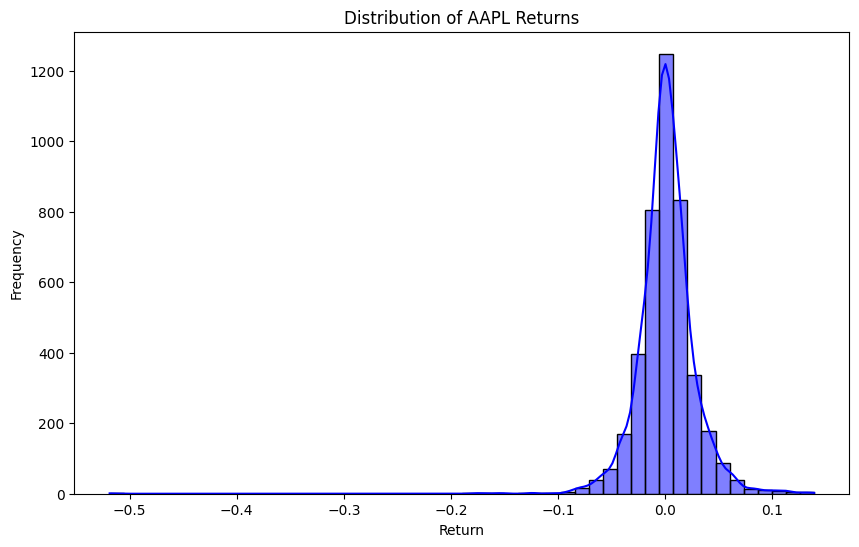

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(merged_data['AAPL_Return'].dropna(), kde=True, bins=50, color='blue')
plt.title("Distribution of AAPL Returns")
plt.xlabel("Return")
plt.ylabel("Frequency")
plt.show()


In [19]:
from scipy import stats

skewness = merged_data['AAPL_Return'].skew()
kurtosis = merged_data['AAPL_Return'].kurtosis()

print(f'Skewness: {skewness:.4f}')
print(f'Kurtosis: {kurtosis:.4f}')

Skewness: -1.6373
Kurtosis: 36.4231


We can see that the distribution of AAPL return is negative-skewed and leptokurtic.

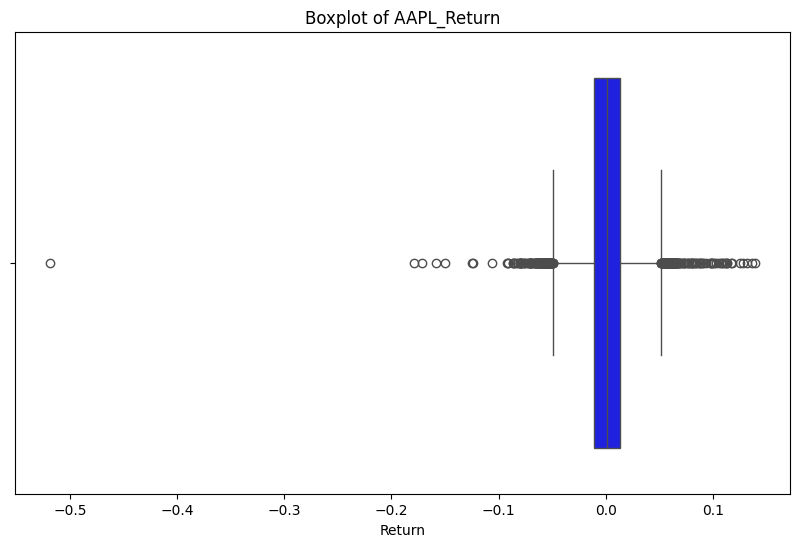

Number of outliers in AAPL_Return: 240


In [20]:
# Outlier Analysis

plt.figure(figsize=(10, 6))
sns.boxplot(x=merged_data['AAPL_Return'], color='blue')
plt.title("Boxplot of AAPL_Return")
plt.xlabel("Return")
plt.show()

q1 = merged_data['AAPL_Return'].quantile(0.25)
q3 = merged_data['AAPL_Return'].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = merged_data[(merged_data['AAPL_Return'] < lower_bound) | (merged_data['AAPL_Return'] > upper_bound)]
print(f"Number of outliers in AAPL_Return: {len(outliers)}")


## 2.2 Correlation Analysis

Check attributes are most correlated with AAPL_Return

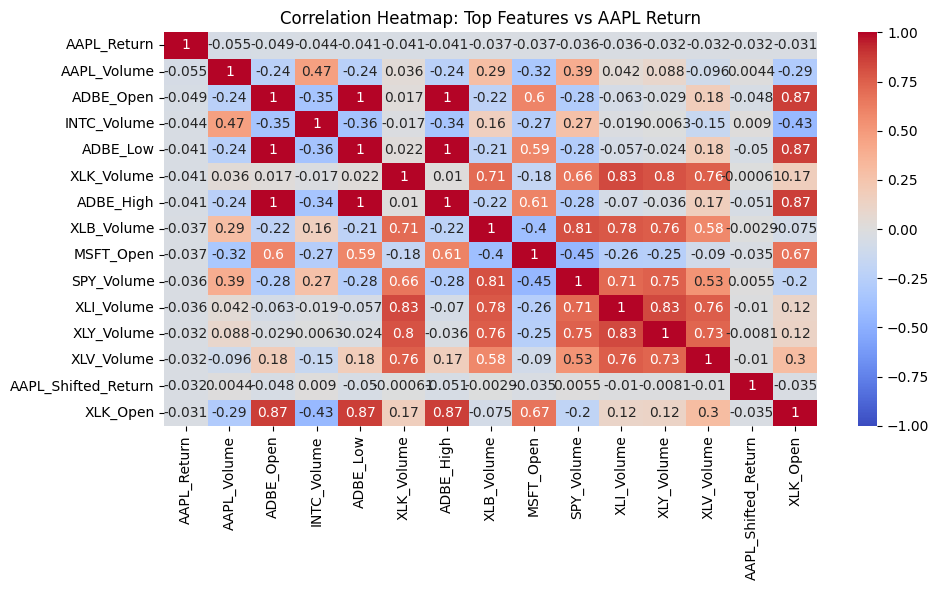


Top correlations with AAPL_Return:
AAPL_Return            1.000000
AAPL_Volume           -0.055192
ADBE_Open             -0.048531
INTC_Volume           -0.043563
ADBE_Low              -0.040717
XLK_Volume            -0.040650
ADBE_High             -0.040602
XLB_Volume            -0.037196
MSFT_Open             -0.036545
SPY_Volume            -0.036193
XLI_Volume            -0.035802
XLY_Volume            -0.032033
XLV_Volume            -0.031615
AAPL_Shifted_Return   -0.031566
XLK_Open              -0.031488
Name: AAPL_Return, dtype: float64


In [21]:
aapl_correlation = merged_data.corr()['AAPL_Return']

correlations_sorted = aapl_correlation.abs().sort_values(ascending=False)

top_feature = correlations_sorted.head(15)

plt.figure(figsize=(10, 6))

# correlation matrix for top correlated features
top_features = top_feature.index
correlation = merged_data[top_features].corr()

# heatmap
sns.heatmap(correlation,
            annot=True,
            cmap='coolwarm',
            center=0,
            vmin=-1, vmax=1)

plt.title('Correlation Heatmap: Top Features vs AAPL Return')
plt.tight_layout()
plt.show()

# actual correlation values
print("\nTop correlations with AAPL_Return:")
print(aapl_correlation[correlations_sorted.index[:15]])


## 2.3 Time Series Analysis

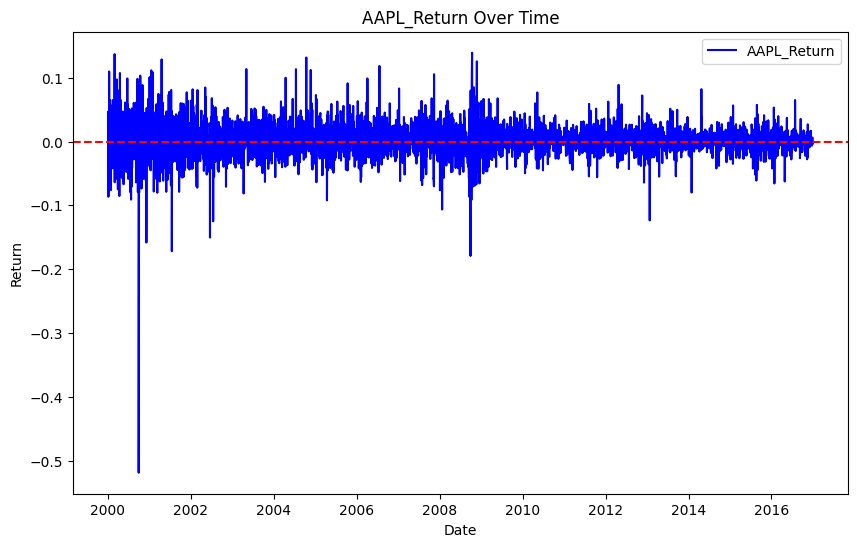

In [22]:
# AAPL_Return over time
plt.figure(figsize=(10, 6))
plt.plot(merged_data.index, merged_data['AAPL_Return'], label='AAPL_Return', color='blue')
plt.axhline(0, color='red', linestyle='--')
plt.title("AAPL_Return Over Time")
plt.xlabel("Date")
plt.ylabel("Return")
plt.legend()
plt.show()

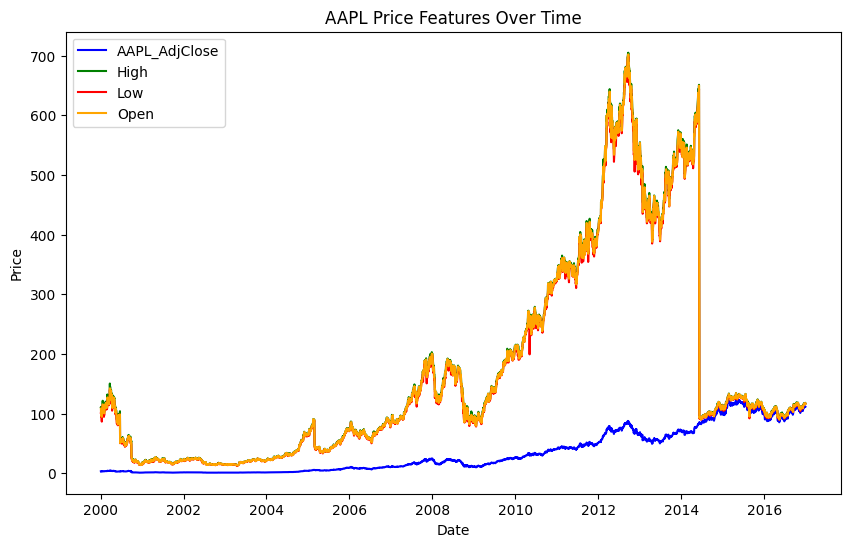

In [23]:
plt.figure(figsize=(10, 6))
plt.plot(merged_data.index, merged_data['AAPL_AdjClose'], label='AAPL_AdjClose', color='blue')
plt.plot(merged_data.index, merged_data['AAPL_High'], label='High', color='green')
plt.plot(merged_data.index, merged_data['AAPL_Low'], label='Low', color='red')
plt.plot(merged_data.index, merged_data['AAPL_Open'], label='Open', color='orange')

plt.title("AAPL Price Features Over Time")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()

The large difference between Adjusted Close (blue line) and other prices shows the impact of stock splits.

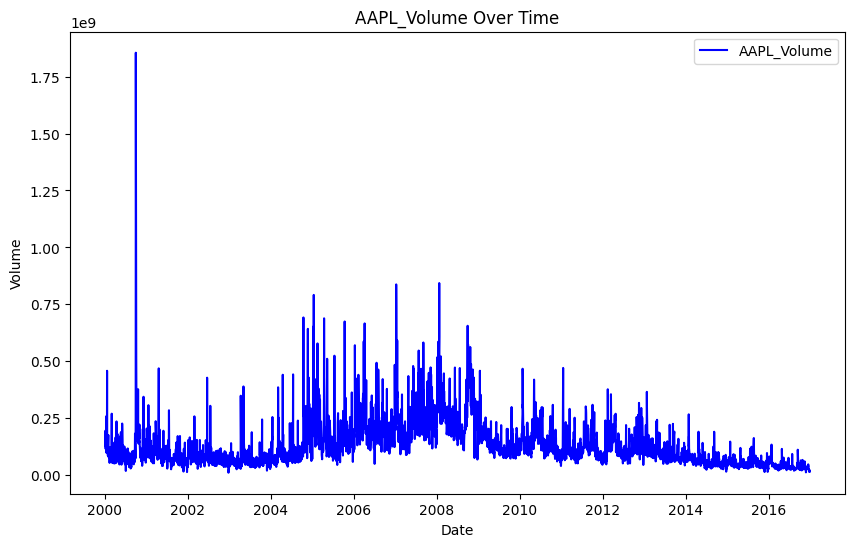

In [24]:
plt.figure(figsize=(10, 6))
plt.plot(merged_data.index, merged_data['AAPL_Volume'], label='AAPL_Volume', color='blue')
plt.title("AAPL_Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.legend()
plt.show()

## 2.3 Volatility Analysis

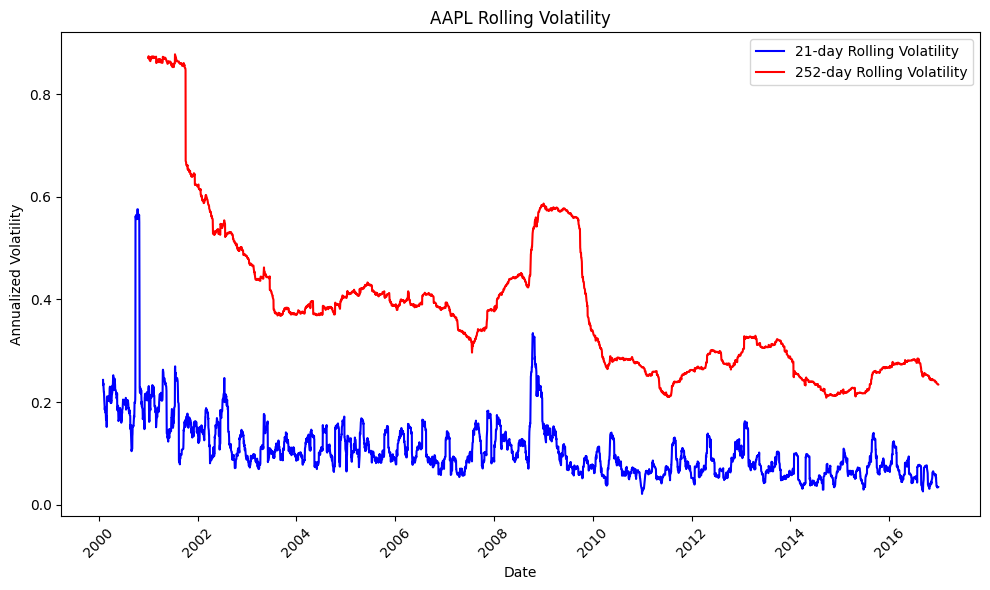

In [25]:
# use 21 days (monthly) and 252 days (annual) windows
monthly_vol = merged_data['AAPL_Return'].rolling(window=21).std() * np.sqrt(21)
annual_vol = merged_data['AAPL_Return'].rolling(window=252).std() * np.sqrt(252)

plt.figure(figsize=(10, 6))
plt.plot(merged_data.index, monthly_vol, label='21-day Rolling Volatility', color='blue')
plt.plot(merged_data.index, annual_vol, label='252-day Rolling Volatility', color='red')

plt.title('AAPL Rolling Volatility')
plt.xlabel('Date')
plt.ylabel('Annualized Volatility')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

We can observe above that the short-term volatility is more jagged but lower in magnitude, whereas the long-term volatility is smoother with a higher magnitude. Also, volatility trends reflected major events that happened in the financial world. For example, during the 2008-2009 Financial Crisis, there were significant spikes in both measures.

# 3. Prepare the Data

We will extract AAPL_specific columns from merged_data and add relevant market features to the new dataframe, eliminating irrelevant features and reducing noise.

In [26]:
aapl_data = merged_data[['AAPL_Return', 'AAPL_AdjClose', 'AAPL_High', 'AAPL_Low', 'AAPL_Open', 'AAPL_Volume', 'AAPL_Shifted_Return']].copy()

In [27]:
aapl_data

,AAPL_Return,AAPL_AdjClose,AAPL_High,AAPL_Low,AAPL_Open,AAPL_Volume,AAPL_Shifted_Return
Dt,,,,,,,
2000-01-04,-0.084318,3.1852,110.6250,101.188,108.2500,128094400.0,0.014630
2000-01-05,0.014630,3.2318,110.5630,103.000,103.7500,194580400.0,-0.086546
2000-01-06,-0.086546,2.9521,107.0000,95.000,106.1183,191993200.0,0.047390
2000-01-07,0.047390,3.0920,101.0000,95.500,96.5000,115183600.0,-0.017594
2000-01-10,-0.017594,3.0376,102.2500,94.750,102.0000,126266000.0,-0.051159
...,...,...,...,...,...,...,...
2016-12-22,-0.006578,111.0876,116.5100,115.640,116.3500,26085900.0,0.001978
2016-12-23,0.001978,111.3073,116.5255,115.590,115.5900,14249500.0,0.006351
2016-12-27,0.006351,112.0142,117.8000,116.490,116.5200,18296900.0,-0.004264


In [28]:
aapl_data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4275 entries, 2000-01-04 to 2016-12-29
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   AAPL_Return          4275 non-null   float64
 1   AAPL_AdjClose        4275 non-null   float64
 2   AAPL_High            4275 non-null   float64
 3   AAPL_Low             4275 non-null   float64
 4   AAPL_Open            4275 non-null   float64
 5   AAPL_Volume          4275 non-null   float64
 6   AAPL_Shifted_Return  4275 non-null   float64
dtypes: float64(7)
memory usage: 267.2 KB


## 3.1 Feature Engineering

After examining the known tickers' information, we will use data from the following tickers:

1. SPY: proxy for overall market behavior, used for creating market features
2. XLK: proxy for industry-level trends, used for creating sector features
3. GOOG and MSFT: key competitors of AAPL, used to create competitor features

We will also create price-based, EWMA, and technical features. Please see details under Section 4.1.1 Baseline Model w/ More Features.

In this section, methods used to create synthetic features are defined.

In [29]:
def create_technical_features(df):
    # price-based features
    df['AAPL_HighLow_Range'] = df['AAPL_High'] - df['AAPL_Low']
    df['AAPL_OpenClose_Range'] = df['AAPL_AdjClose'] - df['AAPL_Open']

    # volatility
    df['AAPL_Volatility_21'] = df['AAPL_Return'].rolling(window=21).std() * np.sqrt(252)

    # RSI
    delta = df['AAPL_AdjClose'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=9).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=9).mean()
    rs = gain / loss
    df['AAPL_RSI'] = 100 - (100 / (1 + rs))

    # Bollinger Bands
    df['AAPL_BB_Middle'] = df['AAPL_AdjClose'].rolling(window=20).mean()
    bb_std = df['AAPL_AdjClose'].rolling(window=20).std()
    df['AAPL_BB_Upper'] = df['AAPL_BB_Middle'] + (bb_std * 2)
    df['AAPL_BB_Lower'] = df['AAPL_BB_Middle'] - (bb_std * 2)

    # EWMA
    for span in [5, 21]:
        df[f'AAPL_EWMA_{span}'] = df['AAPL_AdjClose'].ewm(span=span, adjust=False).mean()
        df[f'AAPL_Volume_EWMA_{span}'] = df['AAPL_Volume'].ewm(span=span, adjust=False).mean()

    return df

In [30]:
def create_market_features(df):
    df['Market_Return'] = df['SPY_AdjClose'].pct_change()

    df['Market_Volatility'] = df['Market_Return'].rolling(window=21).std() * np.sqrt(252)

    return df

def create_sector_features(df):
    df['Sector_Return'] = df['XLK_AdjClose'].pct_change()

    df['Sector_Volatility'] = df['Sector_Return'].rolling(window=21).std() * np.sqrt(252)

    return df

In [31]:
def create_relative_features(df):
    # Beta (20-day rolling)
    df['AAPL_Beta'] = (
        df['AAPL_Return'].rolling(20).cov(df['Market_Return']) /
        df['Market_Return'].rolling(20).var()
    )

    # relative strength vs sector
    df['AAPL_Sector_RS'] = df['AAPL_Return'] - df['Sector_Return']

    return df

In [32]:
def create_competitor_features(df, competitors=['MSFT', 'GOOG', 'INTC']):
   df = df.copy()

   for comp in competitors:
       df[f'{comp}_Return'] = df[f'{comp}_AdjClose'].pct_change()

   return df

We calculate the Spearman correlations between OHLCV information from other tickers and AAPL_Return. We will select the top 10 correlated fields as features.

We use Spearman correlation instead of Pearson correlation because the former is robust to outliers and able to capture non-linear relationships.

In [33]:
all_columns = merged_data.columns

available_tickers = set()
for col in all_columns:
   if '_' in col:
       ticker = col.split('_')[0]
       if ticker != 'AAPL':
           available_tickers.add(ticker)

available_tickers = list(available_tickers)
print("Available tickers:", available_tickers)


ohlcv_correlations = {}

for ticker in available_tickers:
    for feature in ['Open', 'High', 'Low', 'AdjClose', 'Volume']:
        col_name = f'{ticker}_{feature}'
        if col_name in merged_data.columns:
            spearman = merged_data['AAPL_Return'].corr(merged_data[col_name], method='spearman')
            ohlcv_correlations[col_name] = spearman

correlations = pd.Series(ohlcv_correlations).abs().sort_values(ascending=False)
print("\nTop correlated OHLCV features (Spearman):")
print(correlations.head(10))

Available tickers: ['XLB', 'XLV', 'XLE', 'XLI', 'XLF', 'NVDA', 'IBM', 'SPY', 'V', 'MSFT', 'XLP', 'XLK', 'ACN', 'CSCO', 'INTC', 'GOOG', 'XLU', 'MA', 'CRM', 'ADBE', 'XLY']

Top correlated OHLCV features (Spearman):
MSFT_Volume     0.040776
MSFT_Open       0.033921
INTC_Volume     0.033695
MSFT_High       0.026312
IBM_Volume      0.025575
NVDA_Volume     0.024150
GOOG_Volume     0.023554
MSFT_Low        0.023323
XLB_AdjClose    0.021723
XLY_AdjClose    0.020967
dtype: float64


In [34]:
top_correlated_features = correlations.abs().sort_values(ascending=False)[1:11].index.tolist()

# 4. Train Models

## 4.1 Baseline model

Let's start with a simple model, using only OHLCV features from AAPL. The model will help establish a starting point for predictive performance.

### Split Data into training and testing sets
To train and evaluate a model, we will split the original dataset into
a training subset (in-sample), validation subset, and a test subset (out of sample).

In [35]:
# train_end = '2013-12-31'
# val_end = '2014-12-31'

train_ratio = 0.83
val_ratio = 0.06
test_ratio = 0.11

train_size = int(len(merged_data) * train_ratio)
val_size = int(len(merged_data) * (train_ratio + val_ratio))

In [36]:
X_raw = aapl_data.drop(['AAPL_Shifted_Return'], axis=1)
y_raw = aapl_data['AAPL_Shifted_Return']

In [37]:
X_raw_train, y_raw_train = X_raw[:train_size], y_raw[:train_size]
X_raw_val, y_raw_val = X_raw[train_size:val_size], y_raw[train_size:val_size]
X_raw_test, y_raw_test = X_raw[val_size:], y_raw[val_size:]

In [38]:
print(X_raw_train.shape)
print(X_raw_val.shape)
print(X_raw_test.shape)

(3548, 6)
(256, 6)
(471, 6)


In [39]:
# from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_raw_train)
X_val_scaled = scaler.transform(X_raw_val)
X_test_scaled = scaler.transform(X_raw_test)

Since the input of LSTM must be a 3D array, we need to reshape data into the following format: [samples, time_steps, features].

In [40]:
def create_sequences(X, y, time_steps):
    """
    Create sequences of data for LSTMs.

    Parameters:
        X (ndarray): Input features of shape (samples, features).
        y (ndarray): Target array of shape (samples,).
        time_steps (int): Number of timesteps for each sequence.

    Returns:
        Xs (ndarray): Reshaped features of shape (samples - time_steps, time_steps, features).
        ys (ndarray): Aligned targets of shape (samples - time_steps,).
    """
    Xs, ys = [], []
    for i in range(len(X) - time_steps):
        Xs.append(X[i:(i + time_steps)])
        ys.append(y[i + time_steps])
    return np.array(Xs), np.array(ys)

In [41]:
time_steps = 21

X_train_reshaped, y_train_reshaped = create_sequences(X_train_scaled, y_raw_train, time_steps)
X_val_reshaped, y_val_reshaped = create_sequences(X_val_scaled, y_raw_val, time_steps)
X_test_reshaped, y_test_reshaped = create_sequences(X_test_scaled, y_raw_test, time_steps)

print(X_train_reshaped.shape)

(3527, 21, 6)


<ipython-input-40-10f31fd9a310>:17: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ys.append(y[i + time_steps])


Train a simple Neural Network model with 2 LSTM layers and 2 dense layers.

Add dropout layers as neededd to avoid overfitting.

In [42]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Conv1D, MaxPooling1D, Flatten, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score

def create_baseline_model(input_shape):
  model = Sequential([
      LSTM(64, input_shape = input_shape, activation='tanh', recurrent_activation='sigmoid', return_sequences=True),
      Dropout(0.2),

      LSTM(32, activation='tanh', recurrent_activation='sigmoid', return_sequences=False),
      Dropout(0.2),

      Dense(32, activation='relu'),
      Dense(1, activation='linear') # for regression task
  ])
  return model

In [43]:
input_shape = (X_train_reshaped.shape[1], X_train_reshaped.shape[2])
baseline_model = create_baseline_model(input_shape)

baseline_model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 21, 64)              │          18,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 21, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 31,681 (123.75 KB)

 Trainable params: 31,681 (123.75 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
# visualization

def plot_training_results(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    # Plot loss
    ax1.plot(history.history['loss'], label='Training Loss')
    ax1.plot(history.history['val_loss'], label='Validation Loss')
    ax1.set_title('Model Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend(loc='upper right')

    # Plot MAE (since we're predicting returns, we use MAE instead of accuracy)
    ax2.plot(history.history['mae'], label='Training MAE')
    ax2.plot(history.history['val_mae'], label='Validation MAE')
    ax2.set_title('Model MAE')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Mean Absolute Error')
    ax2.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 11s 42ms/step - loss: 0.0026 - mae: 0.0357 - val_loss: 0.0050 - val_mae: 0.0607
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 8.5821e-04 - mae: 0.0213 - val_loss: 0.0062 - val_mae: 0.0674
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 8.5638e-04 - mae: 0.0206 - val_loss: 0.0035 - val_mae: 0.0504
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 8.8971e-04 - mae: 0.0207 - val_loss: 0.0031 - val_mae: 0.0477
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 8.2410e-04 - mae: 0.0203 - val_loss: 0.0019 - val_mae: 0.0367
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 7.8494e-04 - mae: 0.0199 - val_loss: 0.0013 - val_mae: 0.0303
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - loss: 8.7272e-04 - mae: 0.0197 - val_loss: 0.0013 - val_mae: 0.0295
Epoch 8/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 7.8297e-04 - mae: 0.0198 - val_loss: 0.0011 - val_mae: 0.0276
Epoch 9/20
56/56 ━━━━━━━━━━━━━━━━━━

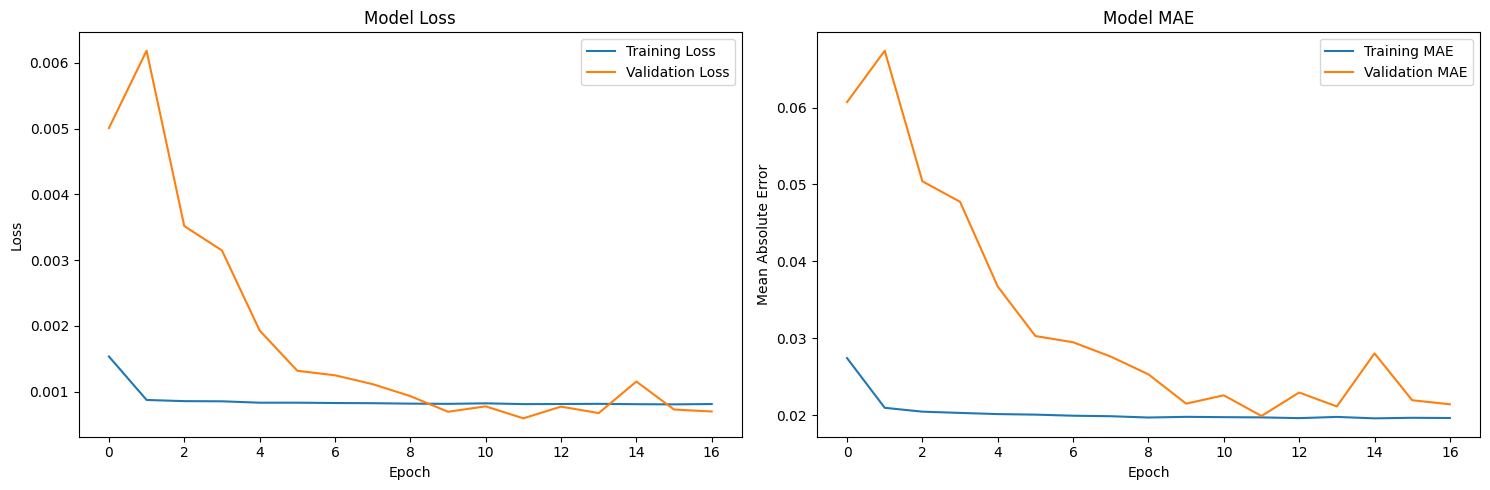

In [45]:
baseline_model.compile(
                 optimizer='adam',
                 loss='mse',
                 metrics=['mae']
                  )

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_baseline = baseline_model.fit(
    X_train_reshaped, y_train_reshaped,
    epochs=20,
    validation_data=(X_val_reshaped, y_val_reshaped),
    batch_size=64,
    callbacks=[early_stopping]
)


plot_training_results(history_baseline)

In [46]:
print("\nFinal Training Values:")
print(f"Training Loss: {history_baseline.history['loss'][-1]:.6f}")
print(f"Validation Loss: {history_baseline.history['val_loss'][-1]:.6f}")
print(f"Training MAE: {history_baseline.history['mae'][-1]:.6f}")
print(f"Validation MAE: {history_baseline.history['val_mae'][-1]:.6f}")


Final Training Values:
Training Loss: 0.000813
Validation Loss: 0.000699
Training MAE: 0.019617
Validation MAE: 0.021403


## Evaluate the Model
Out-of-sample perfermance

In [47]:
test_prediction = baseline_model.predict(X_test_reshaped)
metrics = calculate_metrics(y_test_reshaped, test_prediction)

for metric, value in metrics.items():
    print(f"{metric}: {value:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step
RMSE: 0.0302
MAE: 0.0262
R^2: -2.7745
Direction Accuracy: 0.4894


Visualize predictions vs actual

In [48]:
def plot_predictions(y_true, y_pred):
    plt.figure(figsize=(10, 6))
    plt.plot(y_true, label='Actual Returns', alpha=0.7)
    plt.plot(y_pred, label='Predicted Returns', alpha=0.7)
    plt.title('Predicted Shifted Daily Returns vs Actual Daily Returns')
    plt.xlabel('Time')
    plt.ylabel('Return')
    plt.legend()
    plt.grid(True)
    plt.show()

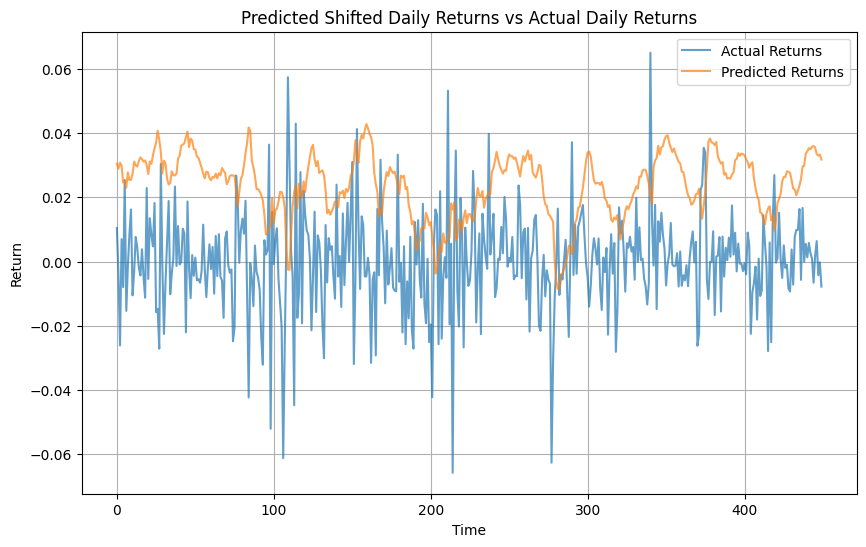

In [49]:
plot_predictions(y_test_reshaped, test_prediction)

The baseline model using raw AAPL features struggles to capture the actual dynamics of stock returns. Here are some potential reasons:
1. Lack of contextual info i.e. market dependencies
2. Insufficient features for capturing trends in time series financial data
3. Simple model Structure



### Loss

Since we want to predict the right direction of return movement, let's define a customized loss that takes direction accuracy into account. We can use this loss when training our models later on.

In [50]:
def directional_loss(y_true, y_pred):
    mse = tf.reduce_mean(tf.square(y_true - y_pred))

    direction_true = tf.sign(y_true)
    direction_pred = tf.sign(y_pred)
    direction_loss = tf.cast(tf.not_equal(direction_true, direction_pred), tf.float32)

    return mse + 0.1 * direction_loss

### 4.1.1 Baseline Model w/ More Features

Let's add synthetic features to the data:
1. top_correlated_features
2. Sector features
3. Market features
4. Price-based features
5. Expoential moving averages (so that we can apply more weighting to the most recent prices)
6. Volatility measures
7. Market/sector-relative features (Beta & relative strength vs. sector)
8. Competitor features
9. Technical indicators

For now, we will still use the baseline model to see if out-of-sample performance improves with our refined dataset.

In [51]:
additional_features = merged_data[top_correlated_features]

data = create_technical_features(aapl_data)

market_comp_tickers = ['SPY', 'XLK', 'GOOG', 'MSFT', 'INTC']

for ticker in market_comp_tickers:
    data[f'{ticker}_AdjClose'] = merged_data[f'{ticker}_AdjClose']

data = create_market_features(data)
data = create_sector_features(data)
data = create_relative_features(data)
data = create_competitor_features(data)

data = pd.concat([data, additional_features], axis=1)

# drop adjusted close columns
columns_to_drop = ['GOOG_AdjClose', 'MSFT_AdjClose', 'SPY_AdjClose', 'XLK_AdjClose', 'INTC_AdjClose']
data = data.drop(columns=columns_to_drop)

data = data.dropna()

data.head()

,AAPL_Return,AAPL_AdjClose,AAPL_High,AAPL_Low,AAPL_Open,AAPL_Volume,AAPL_Shifted_Return,AAPL_HighLow_Range,AAPL_OpenClose_Range,AAPL_Volatility_21,...,MSFT_Open,INTC_Volume,MSFT_High,IBM_Volume,NVDA_Volume,GOOG_Volume,MSFT_Low,XLB_AdjClose,XLY_AdjClose,ACN_Volume
Dt,,,,,,,,,,,,,,,,,,,,,
2000-02-03,0.045529,3.2104,104.250,100.250,100.3130,118798400.0,0.045384,4.000,-97.1026,0.806385,...,102.063,56126000.0,104.188,6213800.0,2706000.0,44871300.0,100.125,14.8863,22.0238,34994300.0
2000-02-04,0.045384,3.3561,110.000,103.625,103.9380,106330000.0,0.056137,6.375,-100.5819,0.819575,...,104.375,55953800.0,108.000,5405300.0,3092400.0,44871300.0,104.141,14.8665,21.9870,34994300.0
2000-02-07,0.056137,3.5445,114.250,105.938,108.0038,110266800.0,0.007110,8.312,-104.4593,0.770582,...,106.813,42810000.0,106.875,5779500.0,5437200.0,44871300.0,104.250,14.5789,21.5218,34994300.0
2000-02-08,0.007110,3.5697,116.125,111.250,114.0000,102160800.0,-0.019581,4.875,-110.4303,0.758400,...,106.438,38026000.0,110.000,5464300.0,11720400.0,44871300.0,106.438,14.5392,22.0115,34994300.0
2000-02-09,-0.019581,3.4998,117.125,112.438,114.1250,74841200.0,0.007772,4.687,-110.6252,0.759274,...,109.438,38615200.0,109.438,5374700.0,14726400.0,44871300.0,103.875,14.2516,21.6442,34994300.0


In [52]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4254 entries, 2000-02-03 to 2016-12-29
Data columns (total 37 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   AAPL_Return           4254 non-null   float64
 1   AAPL_AdjClose         4254 non-null   float64
 2   AAPL_High             4254 non-null   float64
 3   AAPL_Low              4254 non-null   float64
 4   AAPL_Open             4254 non-null   float64
 5   AAPL_Volume           4254 non-null   float64
 6   AAPL_Shifted_Return   4254 non-null   float64
 7   AAPL_HighLow_Range    4254 non-null   float64
 8   AAPL_OpenClose_Range  4254 non-null   float64
 9   AAPL_Volatility_21    4254 non-null   float64
 10  AAPL_RSI              4254 non-null   float64
 11  AAPL_BB_Middle        4254 non-null   float64
 12  AAPL_BB_Upper         4254 non-null   float64
 13  AAPL_BB_Lower         4254 non-null   float64
 14  AAPL_EWMA_5           4254 non-null   float64
 15  AAP

In [53]:
from sklearn.preprocessing import RobustScaler

X = data.drop(['AAPL_Shifted_Return'], axis=1)
y = data['AAPL_Shifted_Return']

X_train, y_train = X[:train_size], y[:train_size]
X_val, y_val = X[train_size:val_size], y[train_size:val_size]
X_test, y_test = X[val_size:], y[val_size:]

scaler1 = RobustScaler()
X_train_scaled = scaler1.fit_transform(X_train)
X_val_scaled = scaler1.transform(X_val)
X_test_scaled = scaler1.transform(X_test)

# reshape the data for LSTM
X_train_re, y_train_re = create_sequences(X_train_scaled, y_train, time_steps)
X_val_re, y_val_re = create_sequences(X_val_scaled, y_val, time_steps)
X_test_re, y_test_re = create_sequences(X_test_scaled, y_test, time_steps)

print(X_train_re.shape)

(3527, 21, 36)


<ipython-input-40-10f31fd9a310>:17: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ys.append(y[i + time_steps])


In [54]:
input_shape_new = (X_train_re.shape[1], X_train_re.shape[2])
baseline_model_new = create_baseline_model(input_shape_new)
baseline_model_new.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                        │ (None, 21, 64)              │          25,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 21, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 39,361 (153.75 KB)

 Trainable params: 39,361 (153.75 KB)

 Non-trainable params: 0 (0.00 B)

Let's add the EarlyStopping callback to stop training when validation loss stops improving

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - loss: 0.0063 - mae: 0.0579 - val_loss: 5.5759e-04 - val_mae: 0.0186
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0013 - mae: 0.0269 - val_loss: 6.6708e-04 - val_mae: 0.0211
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.0012 - mae: 0.0251 - val_loss: 5.5723e-04 - val_mae: 0.0187
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 9.5807e-04 - mae: 0.0228 - val_loss: 3.3176e-04 - val_mae: 0.0138
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 9.6461e-04 - mae: 0.0221 - val_loss: 4.6700e-04 - val_mae: 0.0168
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - loss: 8.0377e-04 - mae: 0.0208 - val_loss: 2.6615e-04 - val_mae: 0.0120
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 8.8142e-04 - mae: 0.0208 - val_loss: 2.7059e-04 - val_mae: 0.0123
Epoch 8/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 8.2876e-04 - mae: 0.0205 - val_loss: 2.5441e-04 - val_mae: 0.0118
Epoch 9/20
5

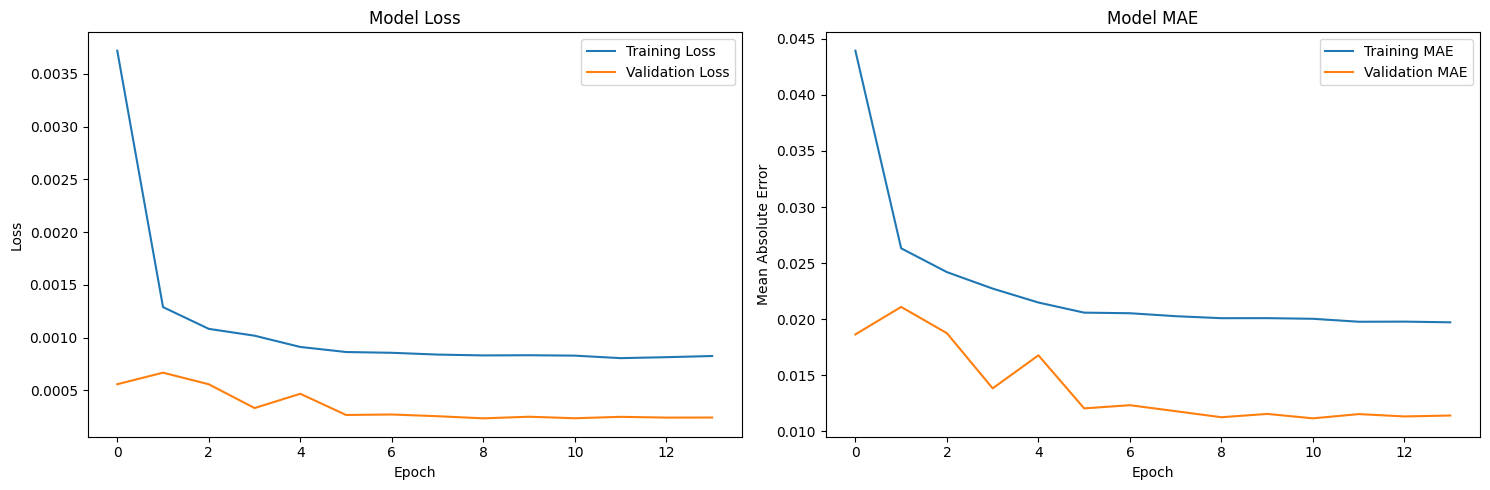

In [55]:
baseline_model_new.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_baseline_new = baseline_model_new.fit(
    X_train_re, y_train_re,
    epochs=20,
    validation_data=(X_val_re, y_val_re),
    batch_size=64,
    callbacks=[early_stopping]
)

plot_training_results(history_baseline_new)

### Evaluation

In [56]:
prediction_new = baseline_model_new.predict(X_test_re)
metrics_new = calculate_metrics(y_test_re, prediction_new)

for metric, value, in metrics_new.items():
  print(f"{metric}: {value:.4f}")

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step
RMSE: 0.0167
MAE: 0.0125
R^2: -0.1387
Direction Accuracy: 0.5009


## Error Analysis (for baseline model)
We will perform Error Analysis and propose a better experiment, learning from failure.



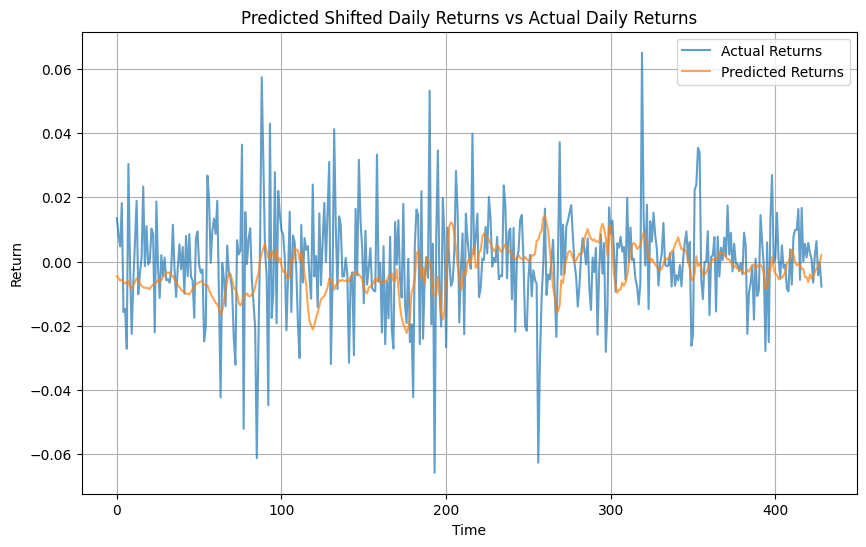

In [57]:
plot_predictions(y_test_re, prediction_new)

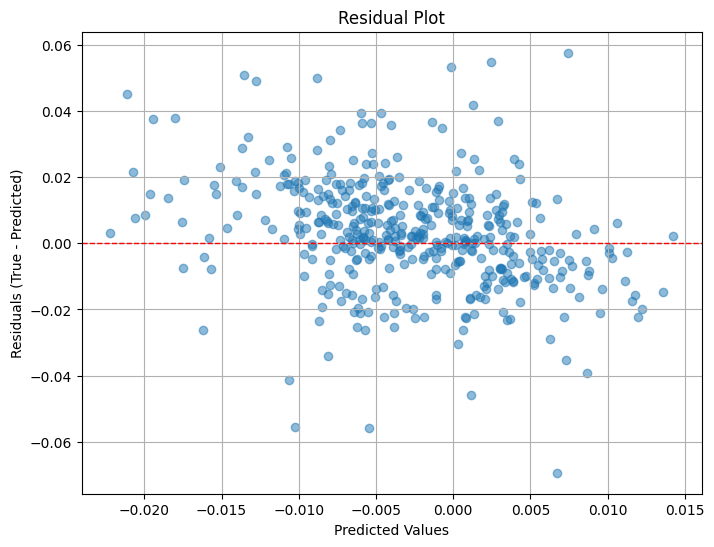

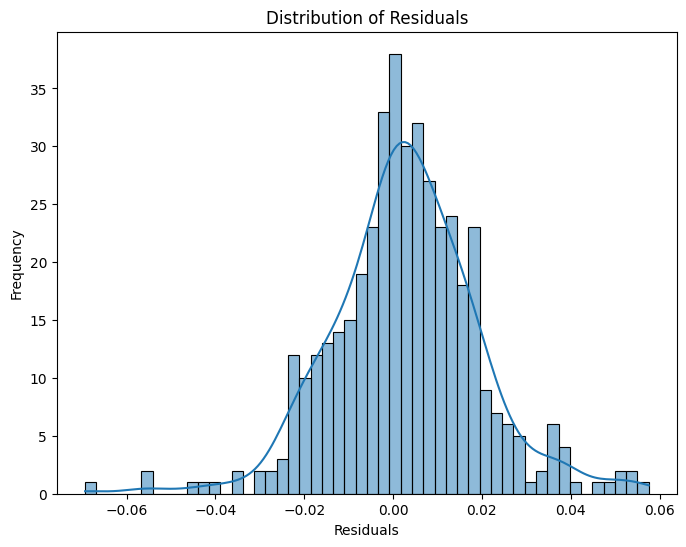

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

prediction_new = prediction_new.flatten()

errors = y_test_re - prediction_new

# residual plot
plt.figure(figsize=(8, 6))
plt.scatter(prediction_new, errors, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1)
plt.title("Residual Plot")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals (True - Predicted)")
plt.grid(True)
plt.show()

# histogram of residuals
plt.figure(figsize=(8, 6))
sns.histplot(errors, bins=50, kde=True)
plt.title("Distribution of Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

We can observe above that there appears to be a slight pattern in the residuals, indicating that the model might not have captured all the relationships in the data.

To achieve better performance, there may be a need for:

1. Non-linear transformations of features
2. A more complex model

In the EDA section, we observe that the distribution of AAPL_return is skewed. Let's try to apply a log transformation on AAPL_Return and target variable to handle skewness and stabilize the variance. Once we predict the log shifted returns, we can later easily convert them back to the original returns.

Note: After experimenting, I have decided not to apply the log transformation. The code for the experiment is in the following blocks and is commented out.


In [59]:
# data['AAPL_Return'] = np.log1p(data['AAPL_Return'])
# data['AAPL_Shifted_Return'] = np.log1p(data['AAPL_Shifted_Return'])
# data.head()

In [60]:
# X = data.drop(columns=['AAPL_Shifted_Return'])
# y = data['AAPL_Shifted_Return']

# X_train, y_train = X[:train_size], y[:train_size]
# X_val, y_val = X[train_size:val_size], y[train_size:val_size]
# X_test, y_test = X[val_size:], y[val_size:]

# scaler = RobustScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_val_scaled = scaler.transform(X_val)
# X_test_scaled = scaler.transform(X_test)

# X_train_re, y_train_re = create_sequences(X_train_scaled, y_train, time_steps)
# X_val_re, y_val_re = create_sequences(X_val_scaled, y_val, time_steps)
# X_test_re, y_test_re = create_sequences(X_test_scaled, y_test, time_steps)

In [61]:
# input_shape_1 = (X_train_re.shape[1], X_train_re.shape[2])
# model = create_baseline_model(input_shape_1)

In [62]:
# model.compile(
#     optimizer='adam',
#     loss='mse',
#     metrics=['mae']
# )

# early_stopping = EarlyStopping(
#     monitor='val_loss',
#     patience=5,
#     restore_best_weights=True
# )

# history_new = baseline_model_new.fit(
#     X_train_re, y_train_re,
#     epochs=20,
#     validation_data=(X_val_re, y_val_re),
#     batch_size=64,
#     callbacks=[early_stopping]
# )

# plot_training_results(history_new)

In [63]:
# log_predictions = model.predict(X_test_re)
# predicted_returns = np.expm1(log_predictions)
# true_returns = np.expm1(y_test_re)

# metric = calculate_metrics(y_test_re, predicted_returns)

# for metric, value in metric.items():
#   print(f"{metric}: {value:.4f}")

## 4.2 Refined Model

Let's add complexity to our model. Consider constructing a hybrid CNN-LSTM model. For time series data, we will use 1D CNN.

We will use Bidirectional LSTM layers for capturing both past and future context by processing sequences in both directions.

In addition, BatchNormalization, dropout, and EarlyStopping are added to stabilize training, provide regularization, and prevent overfitting, respectively.

In [64]:
def create_cnn_lstm_model(input_shape):
   model = Sequential([
       Conv1D(128, kernel_size=3, activation='relu', input_shape=input_shape),
       MaxPooling1D(pool_size=1),

       LSTM(64, input_shape = input_shape, activation='tanh', recurrent_activation='sigmoid', return_sequences=True),
       Dropout(0.2),

       LSTM(32, activation='tanh', recurrent_activation='sigmoid', return_sequences=False),
       BatchNormalization(),
       Dropout(0.2),

       Dense(32, activation='relu'),

       Dense(16, activation='relu'),
       BatchNormalization(),
       Dropout(0.1),

       Dense(1, activation='linear')
   ])

   model.compile(optimizer=Adam(learning_rate=0.001),
                loss='mse',
                metrics=['mae'])

   return model

In [65]:
cnn_lstm_model = create_cnn_lstm_model(input_shape_new)
cnn_lstm_model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 19, 128)             │          13,952 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 19, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_4 (LSTM)                        │ (None, 19, 64)              │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 19, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_5 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 32)                  │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 16)                  │              64 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 77,569 (303.00 KB)

 Trainable params: 77,473 (302.63 KB)

 Non-trainable params: 96 (384.00 B)

Epoch 1/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - loss: 0.6311 - mae: 0.5728 - val_loss: 0.0026 - val_mae: 0.0467
Epoch 2/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 0.1816 - mae: 0.2997 - val_loss: 0.0031 - val_mae: 0.0530
Epoch 3/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 0.1384 - mae: 0.2553 - val_loss: 0.0016 - val_mae: 0.0373
Epoch 4/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - loss: 0.0933 - mae: 0.2081 - val_loss: 5.4280e-04 - val_mae: 0.0195
Epoch 5/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 0.0805 - mae: 0.1883 - val_loss: 8.1953e-04 - val_mae: 0.0238
Epoch 6/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 0.0615 - mae: 0.1583 - val_loss: 5.3442e-04 - val_mae: 0.0186
Epoch 7/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.0490 - mae: 0.1411 - val_loss: 3.1131e-04 - val_mae: 0.0136
Epoch 8/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - loss: 0.0338 - mae: 0.1230 - val_loss: 0.0012 - val_mae: 0.0313
Epoch 9/50
111/111 ━━━━━━━━━━━━

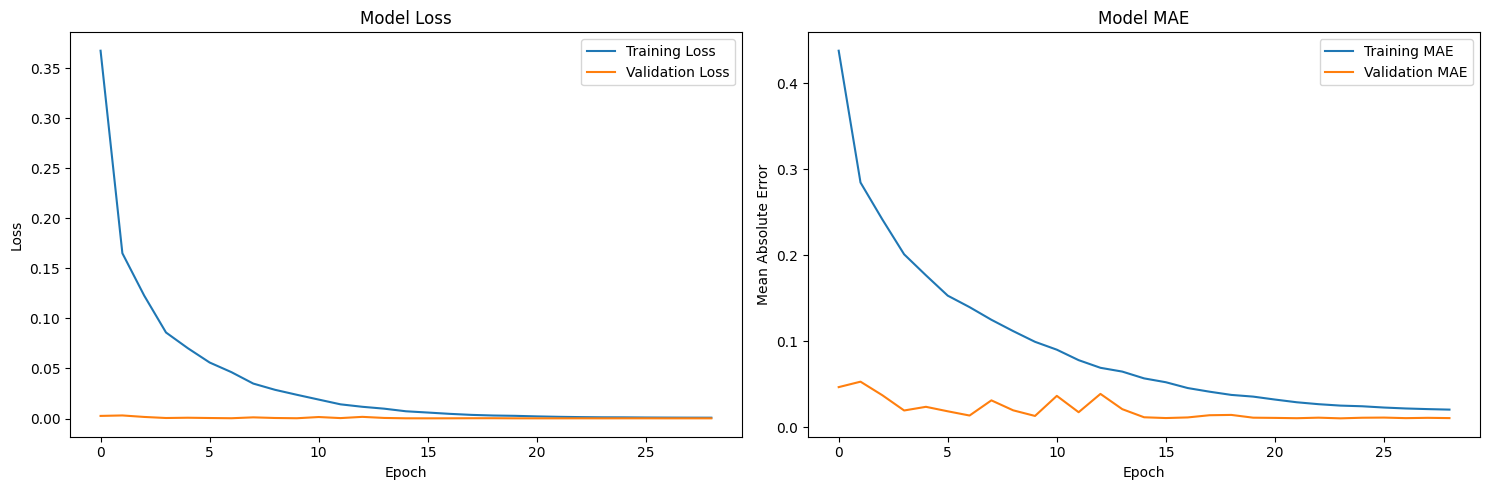

In [66]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_cnn_lstm = cnn_lstm_model.fit(
    X_train_re, y_train_re,
    epochs=50,
    validation_data=(X_val_re, y_val_re),
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

plot_training_results(history_cnn_lstm)

<!-- We want our prediction for date $t$ to be independent on prediction for date $t-1$, as it better mimics real-world prediction scenarios where we have access to actual past data and can make predictions one step at a time. -->

In [67]:
# log_predictions = cnn_lstm_model.predict(X_test_re)
# predicted_returns = np.exp(log_predictions)-1
# true_returns = np.expm1(y_test_re)

# metric = calculate_metrics(y_test_re, predicted_returns)

prediction = cnn_lstm_model.predict(X_test_re)

metric = calculate_metrics(y_test_re, prediction)

for metric, value in metric.items():
  print(f"{metric}: {value:.4f}")


14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step
RMSE: 0.0159
MAE: 0.0115
R^2: -0.0276
Direction Accuracy: 0.4918


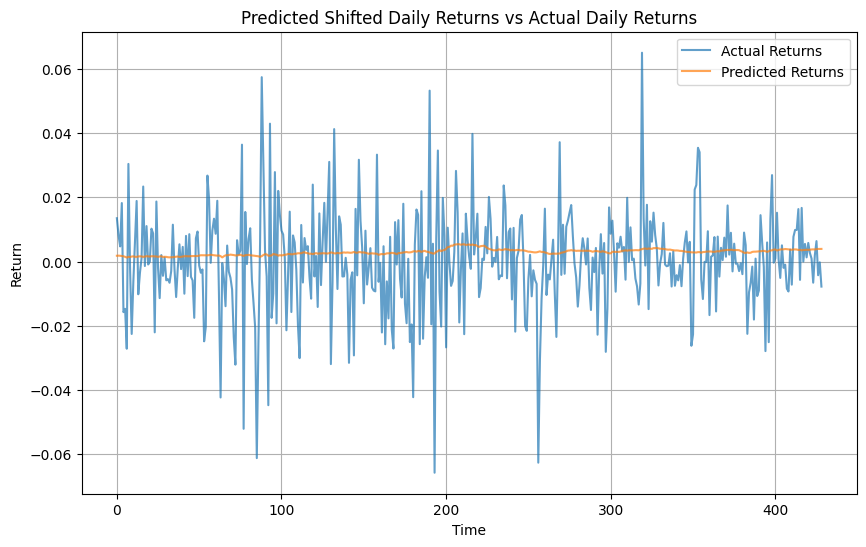

In [68]:
plot_predictions(y_test_re, prediction)

### Using ARIMA as preprocessing step
Let's try using ARIMA to decompose the time series and then feeding the components and residuals into the neural network.

In [69]:
# from statsmodels.tsa.arima.model import ARIMA

# def arima_preprocessing(data, order=(5,1,2)):
#     model = ARIMA(data, order=order)
#     results = model.fit()

#     trend = results.fittedvalues
#     residuals = results.resid

#     return trend, residuals

# train_trend, train_residuals = arima_preprocessing(y_train)
# val_trend, val_residuals = arima_preprocessing(y_val)
# test_trend, test_residuals = arima_preprocessing(y_test)

# # add ARIMA features to reshaped data
# X_train_enhanced = np.dstack([
#     X_train_re,
#     train_trend.reshape(-1, 1),  # Reshape to (n_samples, 1)
#     train_residuals.reshape(-1, 1)
# ])

# X_val_enhanced = np.dstack([
#     X_val_re,
#     val_trend.reshape(-1, 1),
#     val_residuals.reshape(-1, 1)
# ])

# X_test_enhanced = np.dstack([
#     X_test_re,
#     test_trend.reshape(-1, 1),
#     test_residuals.reshape(-1, 1)
# ])

Note: doesn't work since it will cause leakage

## 4.3 CNN+LSTM+attention structure
Since we are dealing with relatively long sequences of complex time series data, adding attention after an LSTM layer in our refined model may be beneficial.

The key idea is that using attention in conjunction with LSTM allows the model to focus on the most relevant time steps of the input sequences, instead of treating the entire sequence equally when making predictions. This approach can be helpful if the input sequence contains irrelevant or distracting information, or when the important parts of the sequence are not always in the same position. By selectively attending to the relevant parts of the input, the model can better capture the underlying patterns and relationships in the data.

In [70]:
from tensorflow.keras.layers import Layer

class AttentionLayer(Layer):
    def __init__(self):
        super(AttentionLayer, self).__init__()

    def call(self, inputs):
        query = inputs
        key = inputs
        value = inputs

        score = tf.matmul(query, key, transpose_b=True)

        attention_weights = tf.nn.softmax(score, axis=-1)

        context = tf.matmul(attention_weights, value)

        return context


def create_cnn_lstm_attention_model(input_shape):
    model = Sequential([
        Conv1D(128, kernel_size=3, activation='relu', input_shape=input_shape),
        MaxPooling1D(pool_size=2),

        LSTM(64, activation='tanh', recurrent_activation='sigmoid', return_sequences=True),
        Dropout(0.2),

        LSTM(32, activation='tanh', recurrent_activation='sigmoid', return_sequences=True),  # Changed to True
        BatchNormalization(),
        Dropout(0.2),

        AttentionLayer(),
        Flatten(),

        Dense(32, activation='relu'),
        Dense(16, activation='relu'),
        BatchNormalization(),
        Dropout(0.1),

        Dense(1, activation='linear')
    ])

    model.compile(optimizer='adam',
                 loss='mse',
                 metrics=['mae'])

    return model

As shown above in our model, CNN layer acts like encoder by extracting features from input sequence and creating meaningful representation. LSTM layer acts like decorder that processes encoded features and makes final prediction.

In [71]:
cnn_lstm_attention_model = create_cnn_lstm_attention_model(input_shape_new)
cnn_lstm_attention_model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)                    │ (None, 19, 128)             │          13,952 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 9, 128)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_6 (LSTM)                        │ (None, 9, 64)               │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 9, 64)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_7 (LSTM)                        │ (None, 9, 32)               │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 9, 32)               │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 9, 32)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ attention_layer (AttentionLayer)     │ (None, 9, 32)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 288)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 32)                  │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 16)                  │              64 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 85,761 (335.00 KB)

 Trainable params: 85,665 (334.63 KB)

 Non-trainable params: 96 (384.00 B)

Epoch 1/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - loss: 0.7216 - mae: 0.5870 - val_loss: 0.0022 - val_mae: 0.0436
Epoch 2/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.2230 - mae: 0.3194 - val_loss: 2.3624e-04 - val_mae: 0.0115
Epoch 3/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.1865 - mae: 0.2878 - val_loss: 0.0022 - val_mae: 0.0448
Epoch 4/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.1217 - mae: 0.2464 - val_loss: 0.0050 - val_mae: 0.0691
Epoch 5/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.1139 - mae: 0.2253 - val_loss: 0.0087 - val_mae: 0.0907


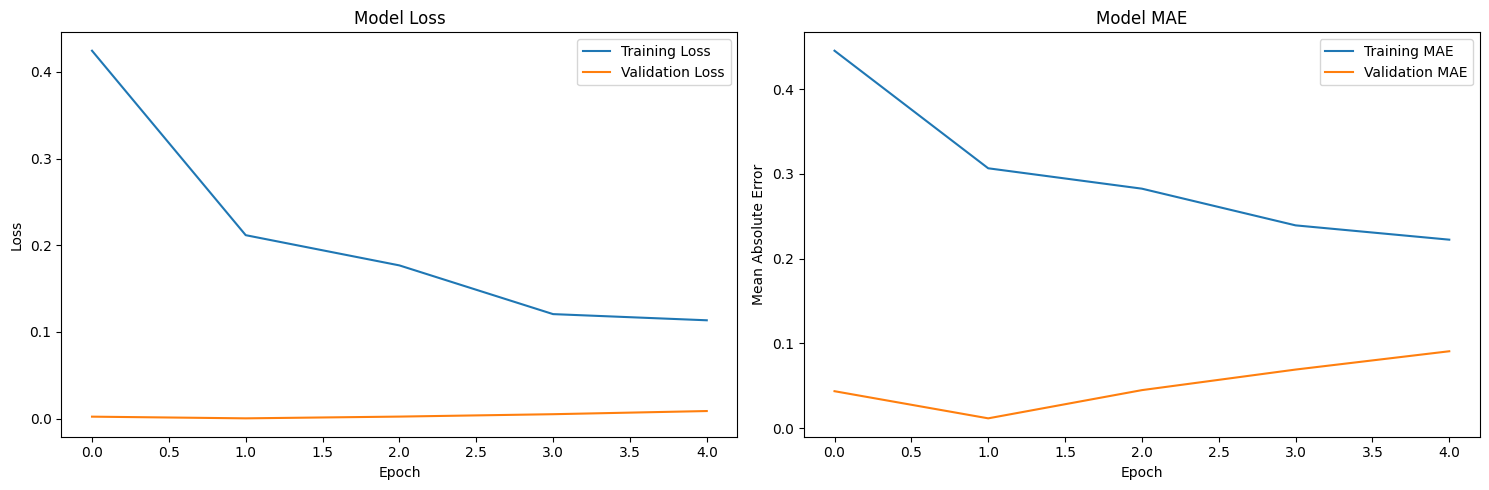

In [72]:
history_cnn_lstm_attention = cnn_lstm_attention_model.fit(
    X_train_re, y_train_re,
    epochs=50,
    validation_data=(X_val_re, y_val_re),
    batch_size=32,
    callbacks=[early_stopping],
)

plot_training_results(history_cnn_lstm_attention)

In [73]:
predicted_returns = cnn_lstm_attention_model.predict(X_test_re)

metric = calculate_metrics(y_test_re, predicted_returns)

for metric, value in metric.items():
  print(f"{metric}: {value:.4f}")

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step
RMSE: 0.0308
MAE: 0.0269
R^2: -2.8513
Direction Accuracy: 0.5058


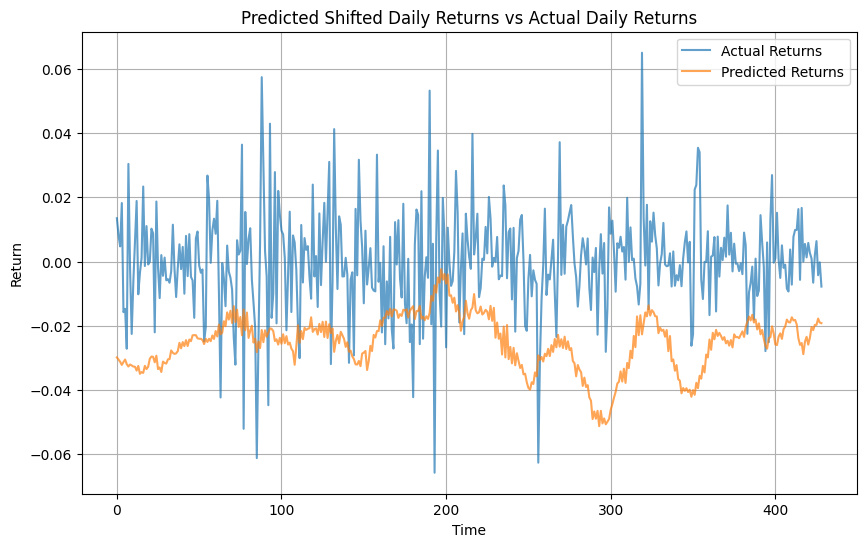

In [74]:
plot_predictions(y_test_re, predicted_returns)

We can conclude from the prediction vs. actual plot above that adding attention may not be useful in our case.

# MyModel

After experiments above, we can see that baseline_model_new performs best out of sample. Therefore, we will chose it as our final model.

In [75]:
import os
from tensorflow.keras.models import load_model

modelName = "final_model"
model_path = os.path.join(".", modelName)

def saveModel(model, model_path):
    """
    Save a model

    Parameters
    ----------
    model: a Keras model object
    model_path: String.  Relative path to a file in which the model will be stored


    Returns
    -------
    model_save_file: String.  Name of the file in which the model has been saved
        - this will be model_path with the proper file-extension added
    """

    model_save_file = model_path + '.keras'

    model.save(model_save_file)

    print(f"Model saved in {model_save_file:s}; submit with your assignment.")

    return model_save_file

def loadModel(model_save_file):
    model = tf.keras.models.load_model( model_save_file )

    return model

In [84]:
def MyModel(test_dir, model_save_file):

    model = loadModel(model_save_file)

    predictions = []

    # The array below (ids) should have a one-to-one correspondence and identify the example your are predicting
    # For Stock prediction: the date on which you are making a prediction
    ids = []

    # YOUR CODE GOES HERE
    # load and merge data
    data_frames = []
    essential_fields = ['Dt', 'Adj Close', 'High', 'Low', 'Open', 'Volume']

    for file in os.listdir(test_dir):
        if file.endswith(".csv"):
            ticker = file.split(".")[0]
            if ticker not in ['XLRE', 'FB']:
                file_path = os.path.join(test_dir, file)
                df = pd.read_csv(file_path, usecols=essential_fields, parse_dates=['Dt'])

                if ticker == 'AAPL':
                    # Only calculate current return
                    df['Return'] = df['Adj Close'].pct_change()

                df = df.rename(columns={
                    'Adj Close': f'{ticker}_AdjClose',
                    'High': f'{ticker}_High',
                    'Low': f'{ticker}_Low',
                    'Open': f'{ticker}_Open',
                    'Volume': f'{ticker}_Volume',
                    'Return': f'{ticker}_Return' if ticker == 'AAPL' else None
                })

                df = df.set_index('Dt')
                data_frames.append(df)

    merged_data = pd.concat(data_frames, axis=1)
    merged_data = merged_data.dropna(subset=['AAPL_Return'])

    # data processing & feature engineering
    merged_data = merged_data.ffill()
    merged_data = merged_data.bfill()

    merged_data = create_technical_features(merged_data)
    merged_data = create_market_features(merged_data)
    merged_data = create_sector_features(merged_data)
    merged_data = create_relative_features(merged_data)
    merged_data = create_competitor_features(merged_data, competitors=['MSFT', 'GOOG', 'INTC'])

    # selected features
    features = ['AAPL_Return', 'AAPL_AdjClose', 'AAPL_High', 'AAPL_Low', 'AAPL_Open',
               'AAPL_Volume', 'AAPL_HighLow_Range', 'AAPL_OpenClose_Range',
               'AAPL_Volatility_21', 'AAPL_RSI', 'AAPL_BB_Middle', 'AAPL_BB_Upper',
               'AAPL_BB_Lower', 'AAPL_EWMA_5', 'AAPL_Volume_EWMA_5', 'AAPL_EWMA_21',
               'AAPL_Volume_EWMA_21', 'Market_Return', 'Market_Volatility', 'Sector_Return',
               'Sector_Volatility', 'AAPL_Beta', 'AAPL_Sector_RS', 'MSFT_Return',
               'GOOG_Return', 'INTC_Return', 'MSFT_Open', 'INTC_Volume', 'MSFT_High',
               'IBM_Volume', 'NVDA_Volume', 'GOOG_Volume', 'MSFT_Low', 'XLB_AdjClose',
               'XLY_AdjClose', 'ACN_Volume']

    X = merged_data[features]

    X_scaled = scaler1.transform(X)

    # create sequences & make prediction
    time_steps = 21
    for i in range(len(X_scaled) - time_steps):
        sequence = X_scaled[i:(i + time_steps)]
        sequence = sequence.reshape(1, time_steps, -1)

        pred = model.predict(sequence, verbose=0)
        predictions.append(pred[0][0])
        ids.append(X.index[i + time_steps])

    return predictions, ids

# Assign to variable my_model the model that is your final model (the one  you will be evaluated on)
my_model = baseline_model_new

model_save_file = saveModel(my_model, model_path)

Model saved in ./final_model.keras; submit with your assignment.


In [85]:
sample_dir = "./Data/sample"
predictions, dates = MyModel(sample_dir, model_save_file)

In [100]:
dates = pd.to_datetime(dates)

Visualization

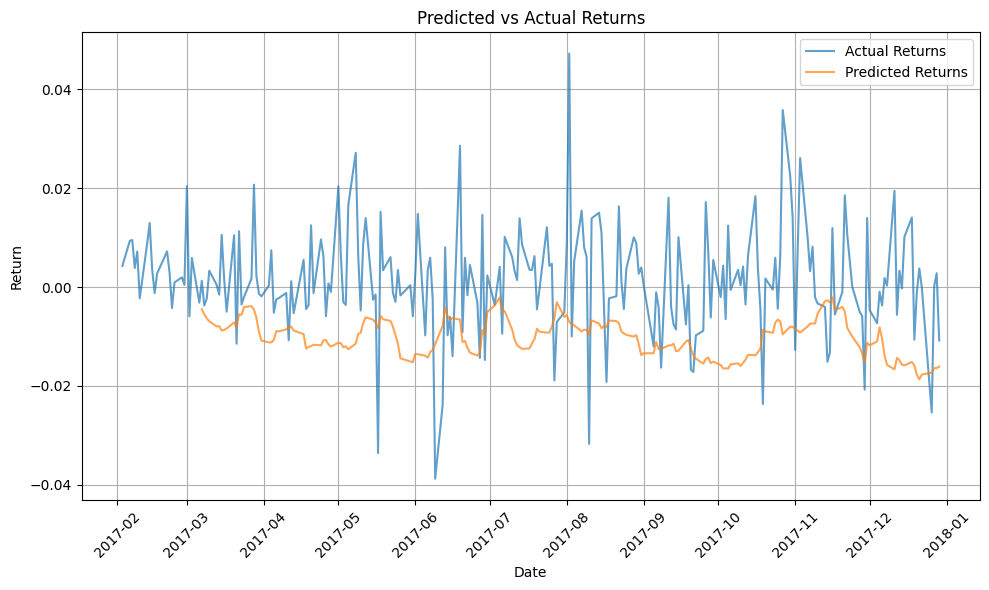

In [104]:
sample_aapl = pd.read_csv(os.path.join(sample_dir, "AAPL.csv"))
sample_aapl['Return'] = sample_aapl['Adj Close'].pct_change()
sample_aapl['Dt'] = pd.to_datetime(sample_aapl['Dt'])
sample_aapl.set_index('Dt', inplace=True)

results_df = pd.DataFrame({
    'Date': dates,
    'Predicted_Return': predictions,
    'Actual_Return': sample_aapl.loc[dates, 'Return']
})
results_df.set_index('Date', inplace=True)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(results_df.index, results_df['Actual_Return'], label='Actual Returns', alpha=0.7)
plt.plot(results_df.index, results_df['Predicted_Return'], label='Predicted Returns', alpha=0.7)
plt.title('Predicted vs Actual Returns')
plt.xlabel('Date')
plt.ylabel('Return')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Once holdout data directory is created, use the following cell to make prediction for holdout set.

In [79]:
# holdout_dir = os.path.join(".", "Data", "holdout")
# predicts = MyModel(holdout_dir, model_save_file)

In [106]:
print("Done")

Done
